In [ ]:
# === CABECALHO ACADEMICO (gerado por scripts/apply_header.py) ===
# Universidade Presbiteriana Mackenzie
# Disciplina: Inteligência Artificial
# Projeto: Previsão de desempenho de jogadores da NBA (pontos por jogo)
#
# INTEGRANTES DO GRUPO:
#   - Rodrigo Lucas Mascarenhas Leite Oliveira - TIA 10427925
#   - André Ihsan Ward - TIA 10425684
#
# ARQUIVO: notebooks/04_incerteza_teto_e_erros.ipynb
# SINTESE: Intervalos, teto preditivo, ablação e análise de erros.
#
# HISTORICO DE ALTERACOES:
#   data       | autor      | descricao
#   -----------|------------|-------------------------------------------
#   2026-11-15 | Rodrigo    | Versão inicial.
# === FIM DO CABECALHO ===


# 04 - Incerteza, teto preditivo, ablação e análise de erros

Compromissos éticos da N1 tratados aqui: (i) acompanhar cada estimativa de uma medida de dispersão; (ii) declarar o teto de desempenho; (iii) reportar métricas por faixa de minutos e por perfil de jogador.

In [2]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_columns", 30)
TV = json.loads(Path("results/metrics/treino_validacao.json").read_text(encoding="utf-8"))
TF = json.loads(Path("results/metrics/test_final.json").read_text(encoding="utf-8"))

## 1. Intervalos conformais

Intervalo `μ ± q·√max(μ, 1)`, limitado a zero: o modelo final prevê μ, e `q` é o quantil do erro normalizado na validação 2024-25 (predição conformal dividida). A cobertura garantida é marginal, não por subgrupo. A raiz de μ faz o intervalo crescer com a previsão, porque quem marca mais oscila mais.

In [3]:
iv = TF["regressao"]["intervalos"]
pd.DataFrame({k: {"nominal": v["nominal"], "q": v["q"], **v["global"]} for k, v in iv.items()}).T

,nominal,q,n,cobertura,largura_media,largura_mediana
80,0.800,2.325,"17,101.000",0.802,15.833,15.430
90,0.900,2.945,"17,101.000",0.902,19.770,19.539


In [4]:
pd.concat({k: pd.DataFrame(v["por_faixa_de_minutos"]).set_index("grupo")[["n", "cobertura", "largura_media"]] for k, v in iv.items()}, axis=1)

80                            90                        
          n cobertura largura_media     n cobertura largura_media
grupo                                                            
15-20  3218     0.779        11.319  3218     0.876        13.472
20-25  4090     0.784        13.890  4090     0.902        17.213
25-30  4521     0.809        16.188  4521     0.907        20.403
30-35  3984     0.822        19.203  3984     0.913        24.310
35+    1288     0.831        21.611  1288     0.914        27.366

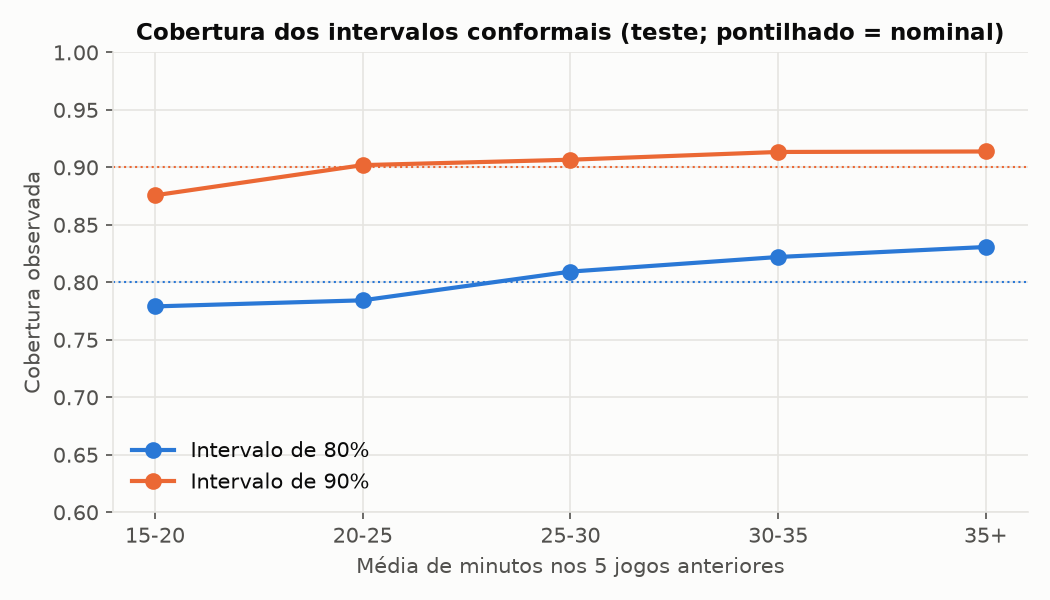

In [5]:
display(Image("results/figures/f_cobertura_intervalos.png", width=640))

## 2. Teto preditivo

Previsores que **trapaceiam** de propósito, com informação do futuro: oráculos simples (média ou mediana do jogador na temporada inteira ou nos 5 jogos antes e depois) e o **modelo com nível oráculo** (o modelo final recebendo também a média real do jogador na temporada). Não são utilizáveis; servem de régua para medir quanto do erro se deve a não conhecer o nível do atleta.

In [6]:
teto = TF["regressao"]["teto_preditivo"]
fin = TF["regressao"]["modelo_final"]
rows = {k: {"MAE": v["mae"], "modelo - oráculo": v["modelo_menos_oraculo"]["delta"], "IC inf": v["modelo_menos_oraculo"]["ic_inf"], "IC sup": v["modelo_menos_oraculo"]["ic_sup"]}
        for k, v in teto.items() if isinstance(v, dict)}
mo = TF["regressao"]["diagnosticos_posteriores"]["modelo_com_nivel_oraculo"]
rows["modelo final + nível oráculo"] = {"MAE": mo["mae_teste"], "modelo - oráculo": mo["modelo_final_menos_oraculo"]["delta"], "IC inf": mo["modelo_final_menos_oraculo"]["ic_inf"], "IC sup": mo["modelo_final_menos_oraculo"]["ic_sup"]}
rows["modelo final (" + fin + ")"] = {"MAE": TF["regressao"]["teste"][fin]["mae"]}
rows["média exponencial"] = {"MAE": TF["regressao"]["teste"]["media_exponencial"]["mae"]}
print(teto["nota"])
pd.DataFrame(rows).T

Oraculos usam jogos futuros do proprio jogador (temporada inteira ou 5 antes/5 depois, sem o proprio jogo). Nao sao utilizaveis na pratica: medem quanto erro sobra mesmo conhecendo o nivel real do atleta. Versao em mediana acrescentada apos a primeira execucao (2026-11-15); nao altera nenhuma escolha de modelo.


,MAE,modelo - oráculo,IC inf,IC sup
oraculo_temporada_media,4.961,-0.038,-0.066,-0.010
oraculo_local_media,5.007,-0.083,-0.112,-0.054
oraculo_temporada_mediana,4.987,-0.064,-0.105,-0.029
oraculo_local_mediana,5.070,-0.147,-0.183,-0.110
modelo final + nível oráculo,4.857,0.066,0.035,0.098
modelo final (hgb_absoluto),4.924,NaN,NaN,NaN
média exponencial,4.977,NaN,NaN,NaN


**Leitura:** os oráculos simples são estimadores ruidosos do nível (o local erra mais que a média exponencial) e não servem de limite superior. O modelo com nível oráculo é a régua útil: conhecer o nível verdadeiro do jogador reduziria o MAE em só ~0,07 ponto. O erro que sobra (~4,9 pontos por jogo) vem principalmente da variação de um jogo para outro (minutos, aproveitamento, contusões, ritmo). Não é um teto absoluto: um oráculo com outras informações (por exemplo, os minutos que o jogador vai jogar) iria mais longe.

## 3. Ablação por família (resultado esperado b)

In [7]:
ab = TF["regressao"]["ablacao_por_familia"]
pd.DataFrame({k: {"MAE sem a família": v["mae_sem_familia"], **{kk: v["aumento_vs_completo"][kk] for kk in ("delta", "ic_inf", "ic_sup", "p_valor")}} for k, v in ab.items()}).T.sort_values("delta", ascending=False)

,MAE sem a família,delta,ic_inf,ic_sup,p_valor
historico_pontos,5.023,0.099,0.078,0.120,0.000
adversario,4.936,0.013,0.007,0.019,0.000
minutos_e_papel,4.931,0.007,0.001,0.014,0.033
descanso_e_mando,4.929,0.005,0.000,0.010,0.049
volume_de_jogo,4.926,0.003,-0.004,0.010,0.392
calendario_do_jogador,4.925,0.001,-0.002,0.004,0.454


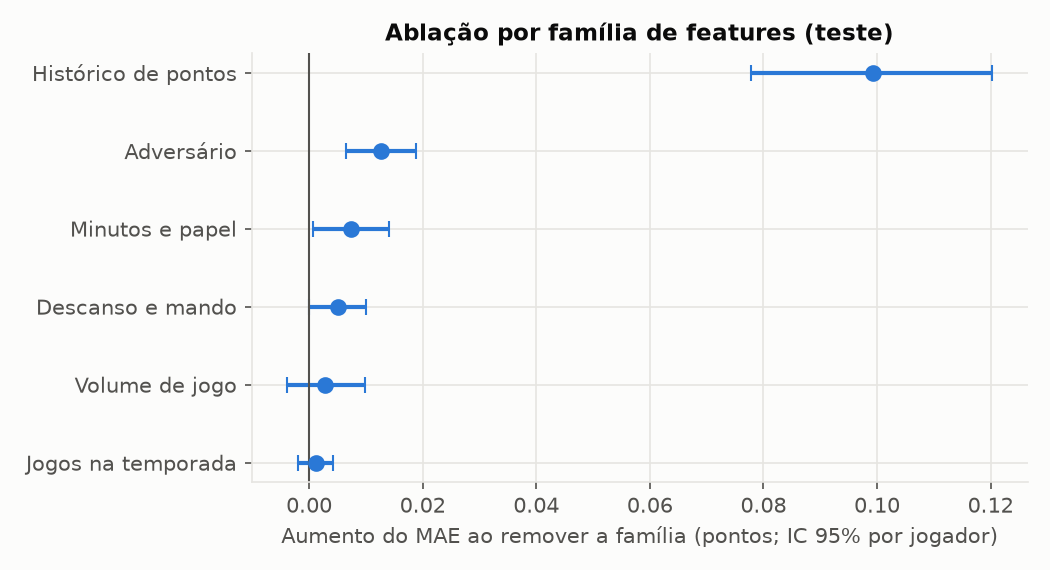

,aumento_mae_medio,desvio
historico_pontos,2.505,0.053
volume_de_jogo,0.066,0.004
minutos_e_papel,0.026,0.003
adversario,0.018,0.002
descanso_e_mando,0.009,0.002
calendario_do_jogador,0.001,0.000


In [8]:
display(Image("results/figures/f_ablacao_familias.png", width=640))
pi = TF["regressao"]["importancia_permutacao_agrupada"]
pd.DataFrame(pi["familias"]).T.sort_values("aumento_mae_medio", ascending=False)

O histórico de pontos domina. Adversário, minutos e descanso/mando têm contribuições pequenas; só a do adversário resiste a uma correção de Bonferroni para as seis comparações. O volume de jogo não tem efeito detectável na ablação (sua informação reaparece nas colunas do histórico), mas a permutação agrupada mostra que o modelo o usa.

## 4. Análise de erros

In [9]:
perf = TF["regressao"]["por_perfil"]
pd.concat({grp: pd.concat({m: pd.DataFrame(v).set_index("grupo")[["n", "mae", "mae_relativo", "vies"]] for m, v in d.items()}, axis=1) for grp, d in perf.items()})

hgb_absoluto                     \
                                                     n   mae mae_relativo   
               grupo                                                        
estrela        media < 20 pts                    14866 4.722        0.426   
               media >= 20 pts                    2235 6.263        0.264   
novo_no_treino jogador ausente do treino          4546 4.580        0.451   
               jogador presente no treino        12555 5.048        0.369   

                                                 media_exponencial        \
                                            vies                 n   mae   
               grupo                                                       
estrela        media < 20 pts             -0.475             14866 4.773   
               media >= 20 pts             0.372              2235 6.329   
novo_no_treino jogador ausente do treino  -0.698              4546 4.640   
               jogador presente no treino -0.243             12555 5.099   

                                                               
                                          mae_relativo   vies  
               grupo                                           
estrela        media < 20 pts                    0.431 -0.226  
               media >= 20 pts                   0.266  0.663  
novo_no_treino jogador ausente do treino         0.457 -0.519  
               jogador presente no treino        0.373  0.039

In [10]:
pd.DataFrame(TF["regressao"]["vies_por_decil_da_previsao"])

,decil,previsto_medio,real_medio,n
0,1,4.591,5.396,1711
1,2,6.375,7.080,1710
2,3,7.640,8.354,1710
3,4,8.867,9.553,1710
4,5,10.291,10.845,1710
5,6,11.760,12.504,1710
6,7,13.592,13.596,1710
7,8,15.991,16.105,1710
8,9,19.226,18.937,1710
9,10,25.349,24.949,1710


In [11]:
pd.DataFrame(TF["regressao"]["maiores_erros"]).head(12)

,PLAYER_NAME,GAME_DATE,OPPONENT,min_ma5_prev,pts_season_mean_prev,previsto,y_pts,erro
0,Bam Adebayo,2026-03-10,WAS,33.600,18.912,23.081,83.000,59.919
1,Brice Sensabaugh,2026-01-14,CHI,27.800,10.132,11.999,43.000,31.001
2,Anthony Edwards,2026-01-17,SAS,33.800,28.879,25.045,55.000,29.955
3,Cooper Flagg,2026-01-29,CHA,28.400,18.767,19.060,49.000,29.940
4,Nikola Jokić,2025-12-25,MIN,34.800,28.862,26.500,56.000,29.500
5,Jamal Murray,2025-12-03,IND,34.600,23.263,22.925,52.000,29.075
6,Kawhi Leonard,2025-12-28,DET,37.800,26.150,25.964,55.000,29.036
7,CJ McCollum,2025-11-25,ATL,29.000,16.500,16.990,46.000,29.010
8,Cooper Flagg,2026-04-03,ORL,35.800,20.281,22.163,51.000,28.837
9,Luka Dončić,2026-03-19,MIA,38.600,32.982,31.302,60.000,28.698


Os maiores erros são jogos excepcionais (atuações de 50+ pontos ou saídas precoces): eventos reais, sem marca no histórico pré-jogo. O viés por decil mostra o modelo abaixo da média real nos decis baixos e médios, efeito de prever a mediana condicional (que minimiza o erro absoluto) numa distribuição assimétrica à direita, e ligeiramente acima nos dois decis superiores, o que indica que o modelo encolhe pouco as previsões dos maiores pontuadores.